# Experiment 9: Markov Model and Reinforcement Learning
**Aim:** Understand Markov models and implement basic reinforcement learning in Python.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bisect import bisect

plt.rcParams['figure.dpi'] = 100
np.random.seed(42)

## Environment
5×6 grid world. Start **S** (bottom-left), goal **G** (bottom-right), pits **P** in between (episode ends in both).
Actions: ↑ → ↓ ←. Moves slip sideways with probability 0.2.

In [2]:
class GridWorld:
    ACTIONS = ['↑', '→', '↓', '←']
    MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]

    def __init__(self, rows=5, cols=6, slip=0.2,
                 r_step=-1, r_goal=20, r_pit=-50, max_steps=100):
        self.rows, self.cols, self.slip = rows, cols, slip
        self.r_step, self.r_goal, self.r_pit = r_step, r_goal, r_pit
        self.max_steps = max_steps
        self.nS, self.nA = rows * cols, 4
        self.start = self.idx(rows - 1, 0)
        self.goal = self.idx(rows - 1, cols - 1)
        self.pits = [self.idx(rows - 1, c) for c in range(1, cols - 1)]
        self.terminal = set([self.goal] + self.pits)
        self._build_model()

    def idx(self, r, c): return r * self.cols + c
    def pos(self, s): return divmod(int(s), self.cols)

    def reward(self, s):                      # reward for entering state s
        if s == self.goal: return self.r_goal
        if s in self.pits: return self.r_pit
        return self.r_step

    def _move(self, s, a):                    # deterministic move (walls = stay)
        r, c = self.pos(s)
        dr, dc = self.MOVES[a]
        r = min(max(r + dr, 0), self.rows - 1)
        c = min(max(c + dc, 0), self.cols - 1)
        return self.idx(r, c)

    def _build_model(self):
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))       # P[s, a, s'] transition probabilities
        self.R = np.zeros((nS, nA))           # expected immediate reward
        for s in range(nS):
            for a in range(nA):
                if s in self.terminal:        # absorbing states
                    self.P[s, a, s] = 1.0
                    continue
                outcomes = {a: 1 - self.slip,
                            (a + 1) % 4: self.slip / 2,
                            (a - 1) % 4: self.slip / 2}
                for a2, p in outcomes.items():
                    s2 = self._move(s, a2)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self.reward(s2)
        # tables for fast sampling
        self._ns = [[np.flatnonzero(self.P[s, a]).tolist() for a in range(nA)] for s in range(nS)]
        self._cum = [[np.cumsum(self.P[s, a][self._ns[s][a]]).tolist() for a in range(nA)] for s in range(nS)]

    def step(self, s, a, rng):
        i = min(bisect(self._cum[s][a], rng.random()), len(self._ns[s][a]) - 1)
        s2 = self._ns[s][a][i]
        return s2, self.reward(s2), s2 in self.terminal


def draw_grid(env, values, ax, title='', policy=None, mask_terminal=False,
              fmt='{:.2f}', fs=8, path=None):
    """Heatmap of per-state values; optionally overlay policy arrows / a path."""
    grid = np.array(values, dtype=float).copy()
    if mask_terminal:
        grid[list(env.terminal)] = np.nan
    grid = grid.reshape(env.rows, env.cols)
    ax.imshow(grid, cmap='viridis')
    lo, hi = np.nanmin(grid), np.nanmax(grid)
    for s in range(env.nS):
        r, c = env.pos(s)
        v = grid[r, c]
        colr = 'white' if np.isnan(v) or (v - lo) / (hi - lo + 1e-12) < 0.5 else 'black'
        if s in env.terminal and mask_terminal:
            ax.text(c, r, 'G' if s == env.goal else 'P', ha='center', va='center',
                    fontsize=14, fontweight='bold', color='lime' if s == env.goal else 'red')
        elif policy is not None:
            ax.text(c, r, env.ACTIONS[policy[s]], ha='center', va='center', fontsize=16, color=colr)
        else:
            ax.text(c, r, fmt.format(v), ha='center', va='center', fontsize=fs, color=colr)
        tag = 'S' if s == env.start else ('G' if s == env.goal else ('P' if s in env.pits else ''))
        if tag and not (s in env.terminal and mask_terminal):
            ax.text(c - 0.42, r - 0.3, tag, fontsize=8, fontweight='bold', color='red', va='center')
    if path:
        ax.plot([env.pos(s)[1] for s in path], [env.pos(s)[0] for s in path],
                '--o', color='magenta', ms=4, lw=1.5)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])


env = GridWorld()
print(f'{env.nS} states, {env.nA} actions, start={env.pos(env.start)}, goal={env.pos(env.goal)}, pits={[env.pos(p) for p in env.pits]}')

30 states, 4 actions, start=(4, 0), goal=(4, 5), pits=[(4, 1), (4, 2), (4, 3), (4, 4)]


## Exercise 1: Markov Model
A uniformly random policy turns the environment into a Markov chain with transition matrix **P**.

In [3]:
P = env.P.mean(axis=1)                      # chain under random policy
print('P shape:', P.shape, '| every row sums to 1:', np.allclose(P.sum(axis=1), 1))

s0 = env.start
print('\nTransition probabilities from the start state', env.pos(s0))
for s2 in np.flatnonzero(P[s0]):
    print(f'  -> {env.pos(s2)}: {P[s0, s2]:.3f}')

P shape: (30, 30) | every row sums to 1: True

Transition probabilities from the start state (4, 0)
  -> (3, 0): 0.250
  -> (4, 0): 0.500
  -> (4, 1): 0.250


**Simulate state changes** (5 random runs, state index vs time).

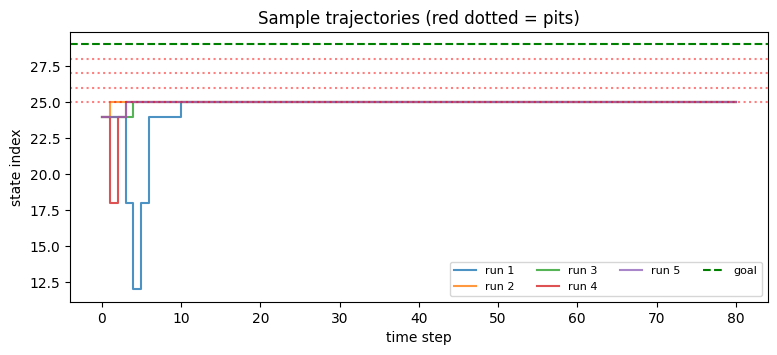

In [4]:
rng = np.random.default_rng(0)

def simulate(P, s, n, rng):
    traj = [s]
    for _ in range(n):
        s = rng.choice(len(P), p=P[s])
        traj.append(s)
    return traj

fig, ax = plt.subplots(figsize=(9, 3.5))
for k in range(5):
    traj = simulate(P, env.start, 80, rng)
    ax.step(range(len(traj)), traj, where='post', alpha=0.8, label=f'run {k+1}')
ax.axhline(env.goal, color='green', ls='--', label='goal')
for p in env.pits: ax.axhline(p, color='red', ls=':', alpha=0.5)
ax.set_xlabel('time step'); ax.set_ylabel('state index'); ax.set_title('Sample trajectories (red dotted = pits)')
ax.legend(ncol=4, fontsize=8); plt.show()

**Visualize** how the state distribution evolves: d(t) = d(0) · Pᵗ.

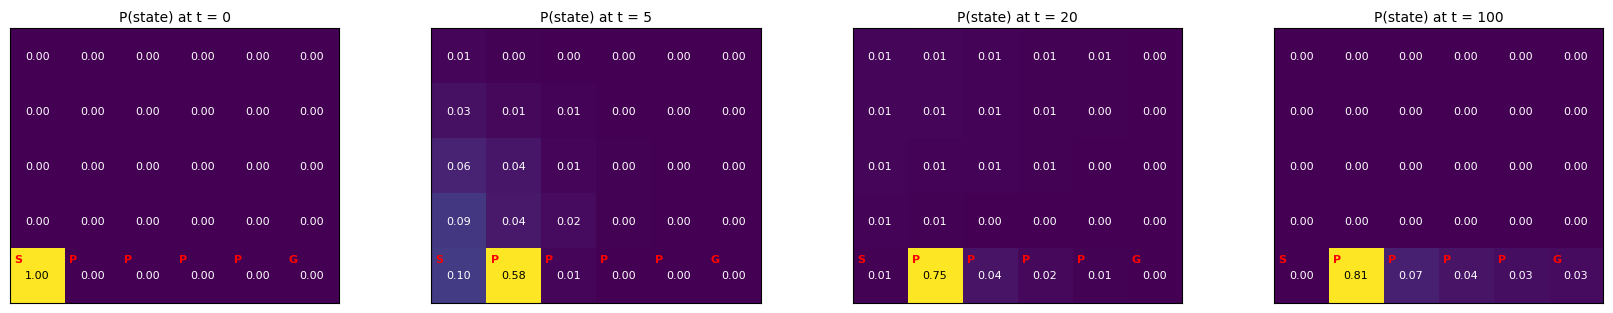

In [5]:
d0 = np.zeros(env.nS); d0[env.start] = 1
fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
for ax, t in zip(axes, [0, 5, 20, 100]):
    draw_grid(env, d0 @ np.linalg.matrix_power(P, t), ax, f'P(state) at t = {t}')
plt.tight_layout(); plt.show()

**Long-term behaviour:** goal and pits are absorbing, so we compute absorption probabilities and expected episode length.

In [6]:
T = sorted(env.terminal)
N = [s for s in range(env.nS) if s not in env.terminal]
Q_, R_ = P[np.ix_(N, N)], P[np.ix_(N, T)]
F = np.linalg.inv(np.eye(len(N)) - Q_)       # fundamental matrix
B = F @ R_                                   # absorption probabilities
exp_steps = F.sum(axis=1)                    # expected steps until absorption

i = N.index(env.start)
p_goal = B[i, T.index(env.goal)]
print(f'Theory   : P(reach goal) = {p_goal:.3f}, P(fall in pit) = {1 - p_goal:.3f}, E[steps] = {exp_steps[i]:.1f}')

# empirical check
rng = np.random.default_rng(1)
outcomes, lengths = [], []
for _ in range(3000):
    s, n = env.start, 0
    while s not in env.terminal:
        s, _, _ = env.step(s, rng.integers(4), rng); n += 1
    outcomes.append(s == env.goal); lengths.append(n)
print(f'Simulated: P(reach goal) = {np.mean(outcomes):.3f}, P(fall in pit) = {1 - np.mean(outcomes):.3f}, E[steps] = {np.mean(lengths):.1f}')

Theory   : P(reach goal) = 0.028, P(fall in pit) = 0.972, E[steps] = 13.5
Simulated: P(reach goal) = 0.028, P(fall in pit) = 0.972, E[steps] = 13.4


**Stationary distribution:** if every finished episode restarts at S, the chain is ergodic and has a unique π with πP = π.

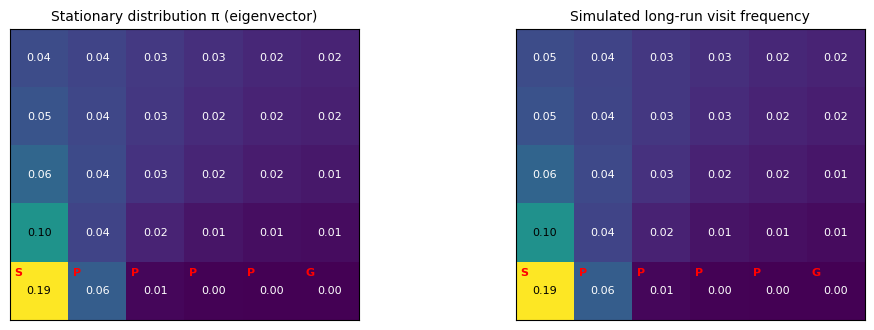

Max |π - frequency| = 0.0022


In [7]:
Pr = P.copy()
for s in env.terminal:
    Pr[s] = 0; Pr[s, env.start] = 1            # restart after absorption

vals, vecs = np.linalg.eig(Pr.T)
pi = np.real(vecs[:, np.argmax(np.real(vals))]); pi /= pi.sum()

rng = np.random.default_rng(2)
counts = np.zeros(env.nS); s = env.start; counts[s] += 1
for _ in range(200_000):
    s = env.start if s in env.terminal else env.step(s, rng.integers(4), rng)[0]
    counts[s] += 1
freq = counts / counts.sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
draw_grid(env, pi, axes[0], 'Stationary distribution π (eigenvector)')
draw_grid(env, freq, axes[1], 'Simulated long-run visit frequency')
plt.tight_layout(); plt.show()
print('Max |π - frequency| =', np.abs(pi - freq).max().round(4))

## Exercise 2: Reward-Based Decision-Making
Reward is given on entering a state: step cost, +goal, −pit. We solve each reward setting with value iteration and compare the resulting decisions (magenta = path from S ignoring slips).

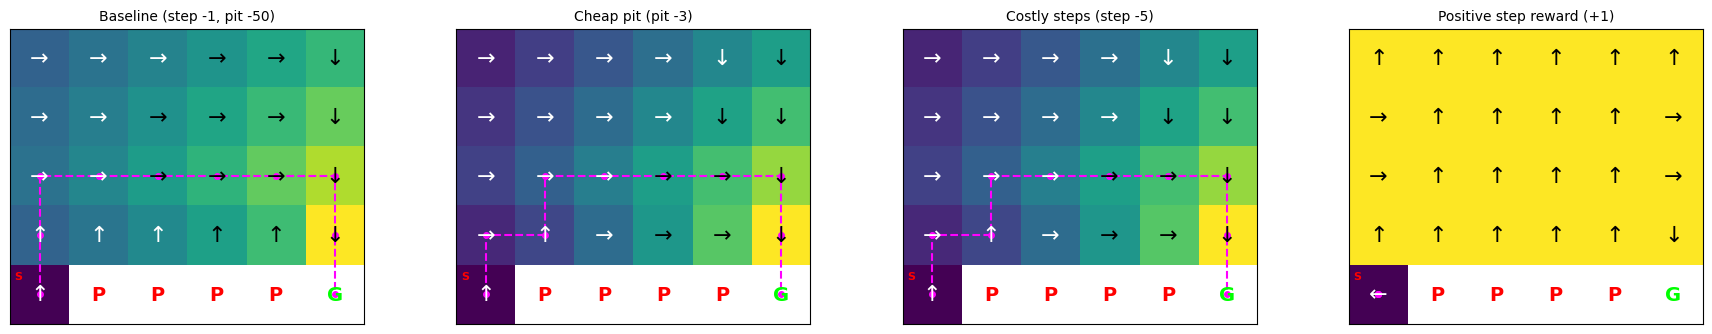

In [8]:
def value_iteration(env, gamma=0.95, tol=1e-9):
    V = np.zeros(env.nS)
    while True:
        Qv = env.R + gamma * env.P @ V
        V_new = Qv.max(axis=1)
        if np.abs(V_new - V).max() < tol: break
        V = V_new
    return V_new, Qv.argmax(axis=1)

def greedy_path(env, policy, max_len=40):
    s, path = env.start, [env.start]
    for _ in range(max_len):
        if s in env.terminal: break
        s = env._move(s, policy[s]); path.append(s)
        if path.count(s) > 2: break           # stuck in a loop
    return path

reward_settings = {
    'Baseline (step -1, pit -50)':     dict(r_step=-1, r_pit=-50),
    'Cheap pit (pit -3)':              dict(r_step=-1, r_pit=-3),
    'Costly steps (step -5)':          dict(r_step=-5, r_pit=-50),
    'Positive step reward (+1)':       dict(r_step=+1, r_pit=-50),
}

fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
for ax, (name, kw) in zip(axes, reward_settings.items()):
    e = GridWorld(**kw)
    V, pol = value_iteration(e)
    draw_grid(e, V, ax, name, policy=pol, mask_terminal=True, path=greedy_path(e, pol))
plt.tight_layout(); plt.show()

Baseline detours one row away from the pits; cheap pits or costly steps make the agent hug the pit row (shorter but riskier); a positive step reward makes it loiter instead of finishing.

## Exercise 3: Q-Learning
Update rule: Q(s,a) ← Q(s,a) + α [ r + γ·maxₐ′ Q(s′,a′) − Q(s,a) ]

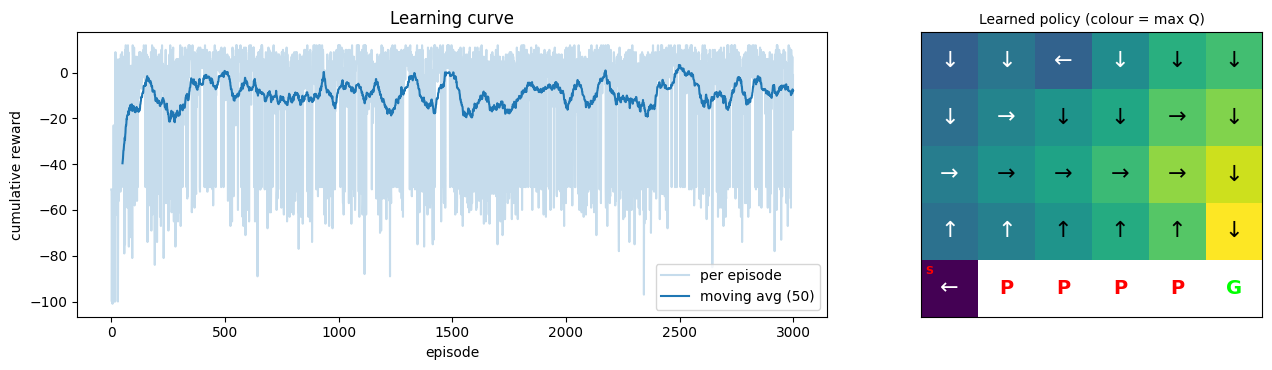

Learned action is (near-)optimal (within 0.5 of Q*) in 88% of states


In [9]:
def q_learning(env, episodes=2000, alpha=0.1, gamma=0.95, eps=0.1, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.nS, env.nA))
    ep_reward, ep_steps, ep_success = np.zeros(episodes), np.zeros(episodes), np.zeros(episodes)
    for ep in range(episodes):
        e = eps(ep) if callable(eps) else eps
        s, total = env.start, 0.0
        for t in range(env.max_steps):
            if rng.random() < e:
                a = rng.integers(env.nA)                          # explore
            else:
                best = np.flatnonzero(Q[s] == Q[s].max())         # exploit (random tie-break)
                a = best[rng.integers(len(best))]
            s2, r, done = env.step(s, a, rng)
            target = r if done else r + gamma * Q[s2].max()
            Q[s, a] += alpha * (target - Q[s, a])
            s, total = s2, total + r
            if done: break
        ep_reward[ep], ep_steps[ep], ep_success[ep] = total, t + 1, float(s == env.goal)
    return dict(Q=Q, reward=ep_reward, steps=ep_steps, success=ep_success)

def smooth(x, w=50):
    return np.convolve(x, np.ones(w) / w, mode='valid')

res = q_learning(env, episodes=3000, alpha=0.1, gamma=0.95, eps=0.1, seed=0)
Q = res['Q']

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={'width_ratios': [1.3, 1]})
axes[0].plot(res['reward'], alpha=0.25, label='per episode')
axes[0].plot(np.arange(49, len(res['reward'])), smooth(res['reward']), color='C0', label='moving avg (50)')
axes[0].set_xlabel('episode'); axes[0].set_ylabel('cumulative reward'); axes[0].set_title('Learning curve'); axes[0].legend()
draw_grid(env, Q.max(axis=1), axes[1], 'Learned policy (colour = max Q)', policy=Q.argmax(axis=1), mask_terminal=True)
plt.tight_layout(); plt.show()

V_opt, pol_opt = value_iteration(env)
Q_star = env.R + 0.95 * env.P @ V_opt
nonterm = [s for s in range(env.nS) if s not in env.terminal]
near_opt = np.mean([Q_star[s, Q[s].argmax()] >= Q_star[s].max() - 0.5 for s in nonterm])
print(f'Learned action is (near-)optimal (within 0.5 of Q*) in {near_opt:.0%} of states')

**Q-values** for each action:

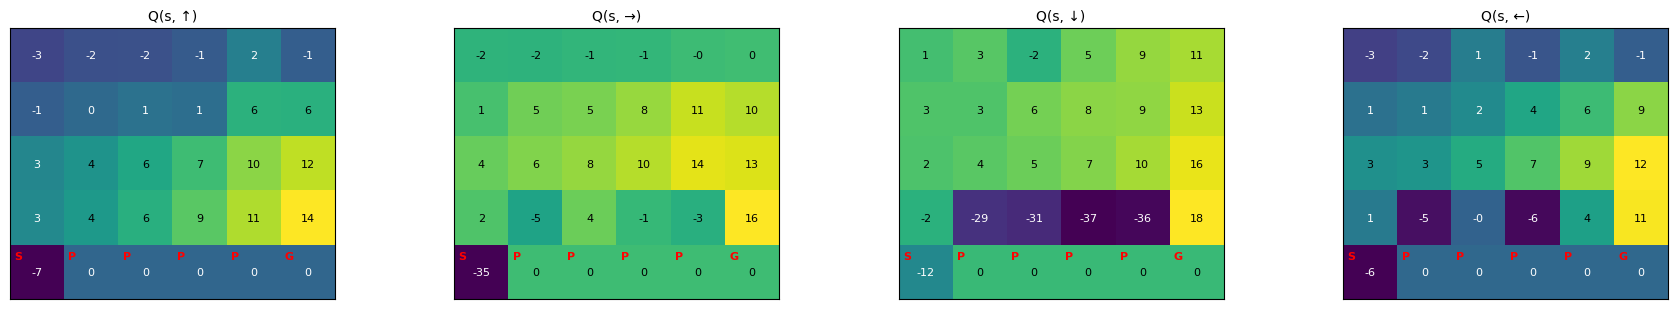

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.2))
for a, ax in enumerate(axes):
    draw_grid(env, Q[:, a], ax, f'Q(s, {env.ACTIONS[a]})', fmt='{:.0f}', fs=8)
plt.tight_layout(); plt.show()

## Exercise 4: Exploration vs. Exploitation
Compare ε values (and a decaying ε), averaged over 3 seeds.

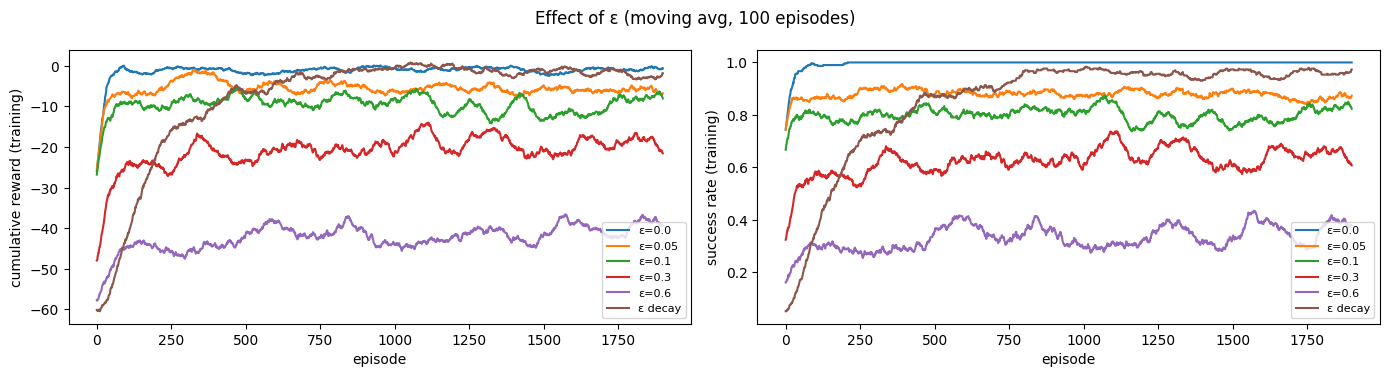

In [11]:
EPISODES, SEEDS = 2000, 3
results = {}                                   # label -> list of runs (reused in Exercise 6)

def run_config(label, env, **kw):
    results[label] = [q_learning(env, episodes=EPISODES, seed=s, **kw) for s in range(SEEDS)]

eps_settings = {'ε=0.0': 0.0, 'ε=0.05': 0.05, 'ε=0.1': 0.1, 'ε=0.3': 0.3, 'ε=0.6': 0.6,
                'ε decay': lambda ep: max(0.01, 0.995 ** ep)}
for label, e in eps_settings.items():
    run_config(label, env, alpha=0.1, gamma=0.95, eps=e)

def plot_curves(labels, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
    for lab in labels:
        rew = np.mean([r['reward'] for r in results[lab]], axis=0)
        suc = np.mean([r['success'] for r in results[lab]], axis=0)
        axes[0].plot(smooth(rew, 100), label=lab)
        axes[1].plot(smooth(suc, 100), label=lab)
    axes[0].set_ylabel('cumulative reward (training)'); axes[1].set_ylabel('success rate (training)')
    for ax in axes: ax.set_xlabel('episode'); ax.legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_curves(eps_settings, 'Effect of ε (moving avg, 100 episodes)')

Larger ε means more random actions, so training reward drops. ε=0 still explores here because Q starts at 0 and all rewards are negative (optimistic start). Decaying ε explores early, exploits later.

## Exercise 5: Discount Factor
Compare γ ∈ {0.1, 0.5, 0.9, 0.99} with ε = 0.1.

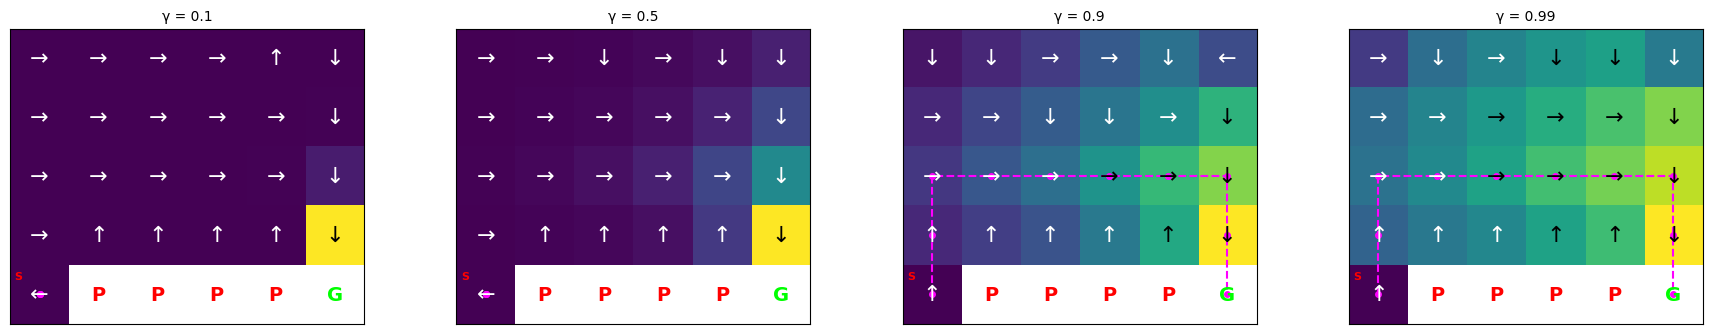

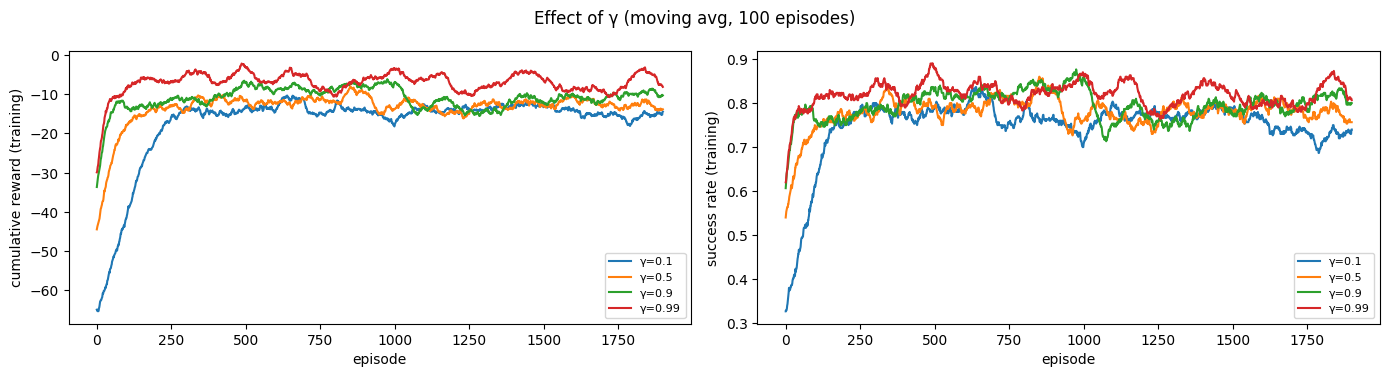

In [12]:
gammas = [0.1, 0.5, 0.9, 0.99]
for g in gammas:
    run_config(f'γ={g}', env, alpha=0.1, gamma=g, eps=0.1)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
for ax, g in zip(axes, gammas):
    Qg = results[f'γ={g}'][0]['Q']
    draw_grid(env, Qg.max(axis=1), ax, f'γ = {g}', policy=Qg.argmax(axis=1),
              mask_terminal=True, path=greedy_path(env, Qg.argmax(axis=1)))
plt.tight_layout(); plt.show()

plot_curves([f'γ={g}' for g in gammas], 'Effect of γ (moving avg, 100 episodes)')

Low γ is short-sighted: at S the agent bumps the wall (←) and waits for a slip rather than risk the pit. High γ values the distant goal and takes the shorter route.

## Exercise 6: Policy Evaluation
Each learned greedy policy is run for 500 test episodes (slips on), averaged over seeds. A random policy and the optimal value-iteration policy are included as references.

,Avg cumulative reward,Avg steps,Success rate (%),Pit rate (%),Training reward (last 200 eps)
Random policy,-58.43,12.78,3.80,94.80,NaN
Optimal (value iter.),2.85,11.57,90.60,9.40,NaN
ε=0.0,-1.14,22.10,99.80,0.00,-0.90
ε=0.05,-0.91,21.87,99.80,0.00,-6.18
ε=0.1,0.10,18.87,97.00,2.87,-8.13
ε=0.3,-1.43,21.74,98.87,0.93,-19.61
ε=0.6,1.78,15.10,94.07,5.87,-39.10
ε decay,-0.97,21.93,99.80,0.00,-2.49
γ=0.1,-2.36,23.32,99.80,0.00,-15.58
γ=0.5,-1.27,22.23,99.80,0.00,-13.21


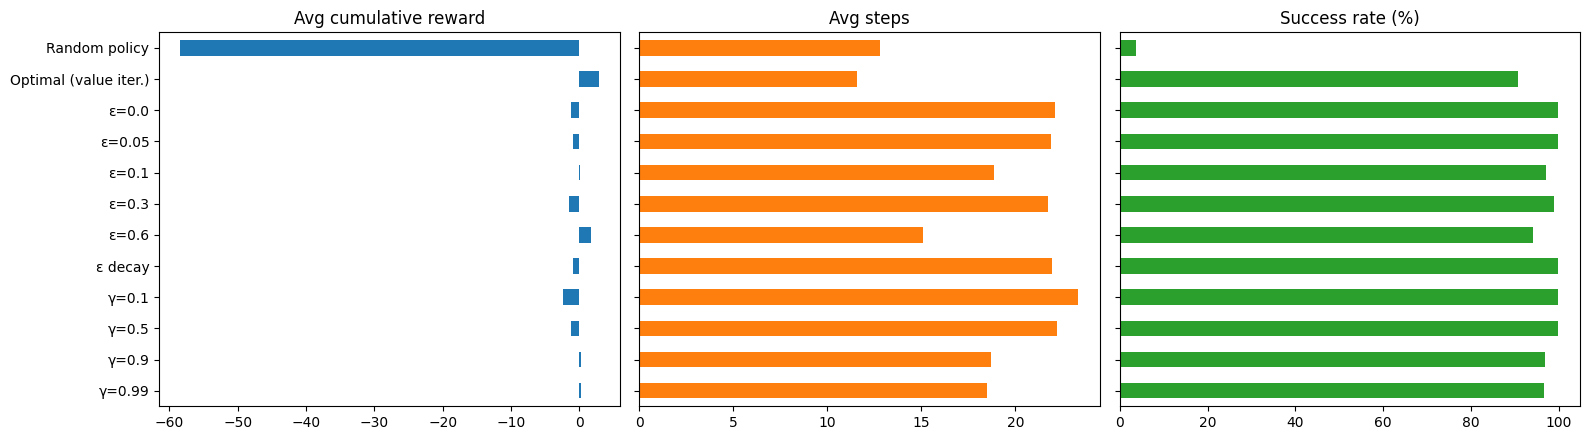

In [13]:
def evaluate(env, policy=None, episodes=500, seed=123):
    rng = np.random.default_rng(seed)
    R, L, S, Pt = [], [], [], []
    for _ in range(episodes):
        s, total = env.start, 0.0
        for t in range(env.max_steps):
            a = rng.integers(env.nA) if policy is None else policy[s]
            s, r, done = env.step(s, a, rng); total += r
            if done: break
        R.append(total); L.append(t + 1); S.append(s == env.goal); Pt.append(s in env.pits)
    return dict(reward=np.mean(R), steps=np.mean(L), success=np.mean(S) * 100, pit=np.mean(Pt) * 100)

rows = {'Random policy': evaluate(env, None) | {'train': np.nan},
        'Optimal (value iter.)': evaluate(env, value_iteration(env)[1]) | {'train': np.nan}}
for label, runs in results.items():
    ev = [evaluate(env, r['Q'].argmax(axis=1)) for r in runs]
    rows[label] = {k: np.mean([e[k] for e in ev]) for k in ev[0]} | {'train': np.mean([r['reward'][-200:].mean() for r in runs])}

df = pd.DataFrame(rows).T[['reward', 'steps', 'success', 'pit', 'train']]
df.columns = ['Avg cumulative reward', 'Avg steps', 'Success rate (%)', 'Pit rate (%)', 'Training reward (last 200 eps)']
display(df.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, c in zip(axes, df.columns[:3], ['C0', 'C1', 'C2']):
    df[col].plot.barh(ax=ax, color=c); ax.set_title(col); ax.invert_yaxis()
axes[1].set_yticklabels([]); axes[2].set_yticklabels([])
plt.tight_layout(); plt.show()

## Conclusion
- Under a random policy the chain ends in a pit ~97% of the time; with restarts it has a unique stationary distribution (matches simulation).
- Reward design shapes behaviour: safe detour, risky shortcut, or loitering.
- Higher ε lowers training reward; decaying ε balances exploration and exploitation.
- Low γ gives myopic, safe-but-slow behaviour; γ ≥ 0.9 learns the faster route with higher reward but ~3% pit falls.